# Figure 3: melanoma RNA + ATAC (DBiT)

From the raw count matrix, ATAC fragments and H&E to the Saturn panels of Fig. 3: objects, targets, Saturn fit (seed 42),
post-hoc tables, chromVAR, H&E registration, iStar, and the figure.

**Envs:** `spatialmultivelo` (this kernel), `cellcharter` (tumour call).
**Time:** about 2 h. Most of that is the fit on 8 CPU threads. iStar takes about 2 min per imputation run on the GPU.
**Hardware:** iStar needs a CUDA GPU, and the tumour call uses it for scVI when available; the rest runs on CPU.

**Left out (comparison methods only):** `mel_baseline_mellon.py` and the Mellon columns of panels l-n; the DPT kernel column
of panel k. `mel_cellrank_kernels.py` still computes DPT, because it is one kernel in an unchanged script, but it is not drawn.
The rho and fusion CellRank kernels stay: they are Saturn results. The fit runs `run_real2.py` without `--bench`, so no GASTON.
Supplementary figS3 is not built.

**Inputs that are not raw:** `melanoma_with_cnv_in_tissue.h5ad`, `starfysh_decon.h5ad` and `targets_melanoma_tissue.npz`, see section 2.

In [1]:
import sys; sys.path[:0] = [".", "steps"]
import nbutil as nb, fig3_checks as chk
nb.init("fig3")
PY, STEPS = sys.executable, nb.Path(nb.__file__).parent / "steps"
OBJ = "results/melanoma"; RS = "results/real_saturn"; DS = "melanoma_tissue"
SAT = f"{nb.ROOT}/Hole/gaston_mix_mm/results/real_saturn"; ISTAR = nb.PF / "fig3/repo/istar"

ok      Yufan_Melanoma/RNA/raw/matrix.mtx.gz  [raw: DBiT melanoma RNA count matrix (genes x spots)]
ok      Yufan_Melanoma/RNA/raw/features.tsv.gz  [raw: RNA features]
ok      Yufan_Melanoma/RNA/raw/barcodes.tsv.gz  [raw: RNA spot barcodes]
ok      Yufan_Melanoma/ATAC/HmelanomaA.fragments.sort.bed.gz  [raw: DBiT melanoma ATAC fragments]
ok      Yufan_Melanoma/spatial/tissue_positions_list.csv  [raw: spot positions on the brightfield image]
ok      Yufan_Melanoma/spatial/tissue_lowres_image.png  [raw: brightfield image]
ok      Yufan_Melanoma/HE_HMelanoma.tif  [raw: adjacent-section H&E]
ok      Saturn/paper_figures/figure2/melanoma_in_tissue/melanoma_with_cnv_in_tissue.h5ad  [lab intermediate, not rerun: Saturn/paper_figures/figure2/melanoma_in_tissue_rerun.py (in-tissue spots, inferCNV with a live BioMart query; also an old Saturn and Mellon fit)]
ok      Saturn/paper_figures/figure2/melanoma_starfysh/starfysh_decon.h5ad  [lab intermediate, not rerun: Saturn/paper_figures/figure2/mela

## 1. RNA and ATAC objects
RNA from the raw matrix and ATAC 5 kb tiles from the fragments with SnapATAC2. Both steps are recovered from
`upstream/melanoma_prep.py` and `upstream/melanoma_multimodal.py`, without their GASTON-Mix-MM fits. Under 5 min.

In [2]:
nb.step("melanoma_rna", f"python {STEPS}/fig3_upstream_rna.py", [f"{OBJ}/melanoma_rna.h5ad"])
nb.step("atac_snap", f"python {STEPS}/fig3_upstream_atac.py", [f"{OBJ}/atac_snap.h5ad"])
if nb.PUB: chk.upstream_objects()

[skip] melanoma_rna: outputs exist
[skip] atac_snap: outputs exist


                                             0                        1
file                melanoma/melanoma_rna.h5ad  melanoma/atac_snap.h5ad
shape                            (2489, 62700)           (2500, 606219)
pub_shape                        (2489, 62700)           (2500, 606219)
same_obs                                  True                     True
same_var                                  True                     True
n_count_diffs                                0                        0
dtype                              int64/int64            uint32/uint32
spatial_max_diff                           0.0                      NaN
mel_score_max_diff                         0.0                      NaN


## 2. Tumour call and Saturn targets
`upstream/melanoma_tumor_id.py` (scVI, CellCharter-style clusters, marker scores, env `cellcharter`) writes the per-spot call.
Its spot list decides which spots are kept, and its marker columns are the programme scores of panels l-n. It reads two
inputs that this notebook does not rebuild: `melanoma_with_cnv_in_tissue.h5ad` (needs a live BioMart query, plus an old Saturn
and Mellon fit in the same script) and `starfysh_decon.h5ad` (a Starfysh run). Note that the first object already holds
log-normalised values in X, which this step stores as counts and normalises again; that is how the published call was made.

Targets: QC keeps spots with a tumour call, RNA depth >= 500 and ATAC depth >= 2000. RNA GLM-PCA with log depth regressed out
and ATAC spectral embedding are recomputed on the kept spots.

**The published target is an input here.** `melanoma_tissue_prep.py` runs GLM-PCA from an unseeded `np.random` start, and
`rna_glmpc_real` retries with penalties 1, 5, 20, 100 when a start diverges, so both the values of `Y_RNA` and the penalty
change between runs. The per-component spread of the published `Y_RNA` matches penalty 20, not the penalty 1 that new runs mostly
reach. Fits on new draws: penalty 1, |r| with published 0.46 (rho_RNA), 0.29 (rho_ATAC), R2 RNA 0.70, ATAC 0.77; two penalty 20
draws, rho_RNA 0.98 and 0.96, rho_ATAC 0.49 and 0.68, R2 RNA 0.80 and 0.79, ATAC 0.81 and 0.82 (published R2 0.79, 0.82).
So the fit below reads the published `targets_melanoma_tissue.npz`, and this section only reruns the script into
`target_recheck/` to show which arrays reproduce.

In [3]:
CALL = "Saturn/paper_figures/figure2/melanoma_tumor_id/per_spot_tumor_call.csv"
nb.step("tumor_call", f"python {nb.PF}/fig3/upstream/melanoma_tumor_id.py", [str(nb.ROOT / CALL)], env="cellcharter")
if nb.PUB: chk.csv_abs(CALL, "cc_K7")
nb.step("target_recheck", f"python {STEPS}/fig3_target_recheck.py", [f"{RS}/target_recheck/targets_{DS}.npz"])
if nb.PUB: chk.target_recheck(DS)

[skip] tumor_call: outputs exist
Saturn/paper_figures/figure2/melanoma_tumor_id/per_spot_tumor_call.csv (1999, 9) (1999, 9) same spots: True
mel_marker        0.0
immune_marker     0.0
stromal_marker    0.0
cnv_burden_v2     0.0
cnv_std           0.0
mel_frac          0.0
immune_frac       0.0
cc_K7             0.0
tumor_mask        0.0
[skip] target_recheck: outputs exist
               key  identical  max_diff
            coords       True  0.000000
          coords_z       True  0.000000
          barcodes       True       NaN
        modalities       True       NaN
             Y_RNA      False 19.614944
            Y_ATAC       True  0.000000
         depth_RNA       True  0.000000
        depth_ATAC       True  0.000000
 ann_cnv_burden_v2       True  0.000000
    ann_mel_marker       True  0.000000
 ann_immune_marker       True  0.000000
ann_stromal_marker       True  0.000000
      ann_mel_frac       True  0.000000
   ann_immune_frac       True  0.000000
         ann_cc_K7      

## 3. Saturn fit
Seed 42 on CPU with `SAT_THREADS=8` and `OMP_NUM_THREADS` unset, as published. Thread settings change the fit, so this is
not the Fig. 2 setting. All post-hoc steps below run with `OMP_NUM_THREADS` unset.

In [4]:
nb.step("fit", f"python scripts/run_real2.py --dataset {DS} --seeds 1 --seed0 42", [f"{RS}/{DS}/axes.csv"], threads=8, device="cpu")
nb.compare_axes(DS)
if nb.PUB: chk.json_numbers(f"{DS}/summary.json", ["R2_whole", "coupling_best"])

[skip] fit: outputs exist
        dataset   axis  max_abs_diff  abs_r
melanoma_tissue  d_RNA           0.0    1.0
melanoma_tissue d_ATAC           0.0    1.0
melanoma_tissue/summary.json R2_whole: this run {'RNA': {'full': 0.7864335915849429, 'own_axis_only': 0.6548892153251725, 'other_axes_only': 0.16068278065446384}, 'ATAC': {'full': 0.8221761094790927, 'own_axis_only': 0.4659734282632726, 'other_axes_only': 0.3344850976604794}} | published {'RNA': {'full': 0.7864335810356159, 'own_axis_only': 0.6548892185935153, 'other_axes_only': 0.16068282110666}, 'ATAC': {'full': 0.8221761266861436, 'own_axis_only': 0.4659734908308901, 'other_axes_only': 0.33448509914694624}} | DIFFERS
melanoma_tissue/summary.json coupling_best: this run [[0.8343, 0.1657], [0.4043, 0.5957]] | published [[0.8343, 0.1657], [0.4043, 0.5957]] | SAME


## 4. Feature tables (panels c, e, f, g)
Gene and peak screens, own vs cross contribution per feature, function-matched peaks and DORC chromatin potential.

In [5]:
nb.step("screens", f"python scripts/marker_function_panels.py {DS} 8 8", [f"{RS}/{DS}_marker_functions/gene_screen.csv", f"{RS}/{DS}_marker_functions/peak_screen.csv"], extra_env=dict(RESCREEN="1"))
nb.step("own_vs_cross", f"python scripts/saturn_own_vs_cross.py {DS}", [f"{RS}/{DS}_own_vs_cross/own_vs_cross.csv"])
nb.step("function_matched", "python scripts/melanoma_chromatin_potential.py 30000", [f"{RS}/{DS}_chromatin_potential/function_matched_peaks.csv"])
nb.step("dorc", "python scripts/melanoma_chromatin_potential_dorc.py", [f"{RS}/{DS}_chromatin_potential/dorc_cp_pairs.csv", f"{RS}/{DS}_chromatin_potential/dorc_curves_RNA.npz"])
for t in ("marker_functions/gene_screen.csv", "marker_functions/peak_screen.csv", "own_vs_cross/own_vs_cross.csv",
          "chromatin_potential/function_matched_peaks.csv", "chromatin_potential/dorc_cp_pairs.csv", "chromatin_potential/dorc_cp_domain_summary.csv"):
    nb.compare_table(f"{DS}_{t}")

[skip] screens: outputs exist
[skip] own_vs_cross: outputs exist
[skip] function_matched: outputs exist
[skip] dorc: outputs exist
melanoma_tissue_marker_functions/gene_screen.csv: shape (1500, 5) vs (1500, 5); max numeric diff 0; MATCH
melanoma_tissue_marker_functions/peak_screen.csv: shape (6000, 8) vs (6000, 8); max numeric diff 0; MATCH
melanoma_tissue_own_vs_cross/own_vs_cross.csv: shape (3500, 18) vs (3500, 18); max numeric diff 0; MATCH
melanoma_tissue_chromatin_potential/function_matched_peaks.csv: shape (1380, 7) vs (1380, 7); max numeric diff 0; MATCH
melanoma_tissue_chromatin_potential/dorc_cp_pairs.csv: shape (197, 8) vs (197, 8); max numeric diff 0; MATCH
melanoma_tissue_chromatin_potential/dorc_cp_domain_summary.csv: shape (7, 9) vs (7, 9); max numeric diff 0; MATCH


## 5. Transition zones and CellRank 2 on the Saturn axes (panels k-n)
The gradient step runs first because the kernel step reads its spots table. `run_fig3.sh` lists them the other way round,
which only works when the gradient output already exists.

In [6]:
nb.step("gradient_zones", "python scripts/mel_gradient_transition.py", [f"{RS}/{DS}_gradient/spots.csv", f"{RS}/{DS}_gradient/zones.csv"])
nb.step("cellrank_kernels", "python scripts/mel_cellrank_kernels.py", [f"{RS}/{DS}_cellrank_kernels/kernels_summary.csv"])
nb.step("cellrank_arrows", "python scripts/mel_cellrank_arrows.py", [f"{RS}/{DS}_cellrank_kernels/arrows.npz"])
for t in ("gradient/spots.csv", "gradient/zones.csv", "cellrank_kernels/kernels_summary.csv", "cellrank_kernels/obs.csv"):
    nb.compare_table(f"{DS}_{t}")
if nb.PUB: chk.npz(f"{DS}_cellrank_kernels/arrows.npz")

[skip] gradient_zones: outputs exist
[skip] cellrank_kernels: outputs exist
[skip] cellrank_arrows: outputs exist
melanoma_tissue_gradient/spots.csv: shape (1997, 19) vs (1997, 19); max numeric diff 0; MATCH
melanoma_tissue_gradient/zones.csv: shape (12, 19) vs (12, 19); max numeric diff 0; MATCH
melanoma_tissue_cellrank_kernels/kernels_summary.csv: shape (6, 7) vs (6, 7); max numeric diff 0; MATCH
melanoma_tissue_cellrank_kernels/obs.csv: shape (1997, 33) vs (1997, 33); max numeric diff 0; MATCH
melanoma_tissue_cellrank_kernels/arrows.npz
           key  diff
            xy   0.0
      barcodes   0.0
         V_DPT   0.0
     V_rho_RNA   0.0
    V_rho_ATAC   0.0
V_fusion_w0.50   0.0


## 6. chromVAR TF activity per spot (input to iStar)
JASPAR 2022 motifs on the top 12,000 tiles, GC and accessibility matched backgrounds. `melanoma_istar_features.py` needs the
per-spot z scores; `run_fig3.sh` does not list these two steps. The motif scan takes a few minutes.

In [7]:
nb.step("tf_activity_rho", f"python scripts/saturn_tf_activity_rho.py {DS}", [f"{RS}/{DS}_tf_activity/tf_fits.csv"])
nb.step("tf_activity_spot", f"python scripts/saturn_tf_activity_spatial.py {DS}", [f"{RS}/{DS}_tf_activity/tf_z_per_spot.npz"])
if nb.PUB: chk.npz(f"{DS}_tf_activity/tf_z_per_spot.npz", ["z", "tfs", "barcodes"])

[skip] tf_activity_rho: outputs exist
[skip] tf_activity_spot: outputs exist
melanoma_tissue_tf_activity/tf_z_per_spot.npz
     key  diff
       z   0.0
     tfs   0.0
barcodes   0.0


## 7. H&E registration and iStar (panels a, h-j)
Brightfield to adjacent H&E (similarity transform on tissue masks), then iStar inputs at 0.5 um/px, for all spots and with
10% of spots held out (seed 0). `melanoma_istar_prep.py` writes `locs.tsv` itself because the local `rescale.py --locs` swaps
x and y (see the fig3 repo README); iStar's own `rescale.py` runs with `--image --radius` only. `run_fig3.sh` omits `--radius`, but
`impute.py` needs `radius.txt`; the published run wrote it (`run_istar.sh`).

iStar trains on the GPU without fixed seeds, so its maps differ between runs. The published held-out correlation is 0.77 and a
rerun gave 0.78. The boundary-width comparison changes more: 54 um vs 62 um interpolated, P = 0.081 in the rerun, against 52 um,
P = 0.00047 published.

In [8]:
REG = f"{SAT}/{DS}_istar/registration"; P = f"{SAT}/{DS}_istar/"; IMG = dict(TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD="1")
nb.step("he_register", f"python scripts/melanoma_he_register.py {REG}", [f"{RS}/{DS}_istar/registration/registration.json"])
if nb.PUB: chk.json_numbers(f"{DS}_istar/registration/registration.json", ["similarity-free-scale"])
nb.step("istar_prep", f"python scripts/melanoma_istar_prep.py {REG}/registration.json similarity", [f"{RS}/{DS}_istar/geometry.json"])
nb.step("istar_prep_holdout", f"python scripts/melanoma_istar_prep.py {REG}/registration.json similarity --holdout 0.1", [f"{RS}/{DS}_istar_holdout10/heldout_spots.txt"])
nb.step("istar_hist_features", f"python rescale.py {P} --image --radius && {PY} preprocess.py {P} --image && {PY} extract_features.py {P} --device=cuda",
        [f"{RS}/{DS}_istar/embeddings-hist.pickle"], cwd=ISTAR, extra_env=IMG)
nb.step("istar_link_holdout", f"cd {SAT}/{DS}_istar_holdout10 && for f in he.jpg he-scaled.jpg embeddings-hist.pickle; do ln -sf {P}$f $f; done; cp {P}radius.txt radius.txt", [f"{RS}/{DS}_istar_holdout10/embeddings-hist.pickle"])
nb.step("istar_features", "python scripts/melanoma_istar_features.py", [f"{RS}/{DS}_istar_feat/cnts_ab.tsv", f"{RS}/{DS}_istar_feat_holdout10/cnts_ab.tsv"])
for d in (f"{DS}_istar_feat", f"{DS}_istar_feat_holdout10"):
    nb.step(f"impute_{d}", f"python impute.py {SAT}/{d}/ --epochs=400 --device=cuda --shape=square", [f"{RS}/{d}/cnts-super/RNA_TYR.pickle"], cwd=ISTAR, extra_env=IMG)
nb.step("istar_boundary", "python scripts/melanoma_istar_boundary.py", [f"{RS}/{DS}_istar_feat/tumour_stroma_maps.npz"])
nb.step("istar_eval", "python scripts/melanoma_istar_eval_features.py", [f"{RS}/{DS}_istar_feat_holdout10/heldout_eval_features.csv"])

[skip] he_register: outputs exist
melanoma_tissue_istar/registration/registration.json similarity-free-scale: this run {'bf_to_he_full': [[2.2545316053333133, 0.13737413943440321, 5540.069149316926], [-0.13737413943440321, 2.2545316053333133, 5743.765458203703], [0.0, 0.0, 1.0]], 'scale': 2.2587129993941573, 'rot': -3.486861317222058, 'corr': 0.7088551533270107} | published {'bf_to_he_full': [[2.2545316053333133, 0.13737413943440321, 5540.069149316926], [-0.13737413943440321, 2.2545316053333133, 5743.765458203703], [0.0, 0.0, 1.0]], 'scale': 2.2587129993941573, 'rot': -3.486861317222058, 'corr': 0.7088551533270107} | SAME
[skip] istar_prep: outputs exist
[skip] istar_prep_holdout: outputs exist
[run ] istar_hist_features: python rescale.py /tmp/claude-1012/-mnt-HDD2B-Users-yancui/486f3289-97a4-41e8-a0a8-b5998a356a68/scratchpad/nbtest/fig3/Hole/gaston_mix_mm/results/real_saturn/melanoma_tissue_istar/ --image --radius && /home/yancui/miniconda3/envs/spatialmultivelo/bin/python preprocess

[done] istar_hist_features: 0.5 min


[run ] istar_link_holdout: cd /tmp/claude-1012/-mnt-HDD2B-Users-yancui/486f3289-97a4-41e8-a0a8-b5998a356a68/scratchpad/nbtest/fig3/Hole/gaston_mix_mm/results/real_saturn/melanoma_tissue_istar_holdout10 && for f in he.jpg he-scaled.jpg embeddings-hist.pickle; do ln -sf /tmp/claude-1012/-mnt-HDD2B-Users-yancui/486f3289-97a4-41e8-a0a8-b5998a356a68/scratchpad/nbtest/fig3/Hole/gaston_mix_mm/results/real_saturn/melanoma_tissue_istar/$f $f; done; cp /tmp/claude-1012/-mnt-HDD2B-Users-yancui/486f3289-97a4-41e8-a0a8-b5998a356a68/scratchpad/nbtest/fig3/Hole/gaston_mix_mm/results/real_saturn/melanoma_tissue_istar/radius.txt radius.txt


[done] istar_link_holdout: 0.0 min


[run ] istar_features: python scripts/melanoma_istar_features.py


[done] istar_features: 0.0 min


... (4 outputs left out)

[run ] istar_boundary: python scripts/melanoma_istar_boundary.py


[done] istar_boundary: 0.0 min


[run ] istar_eval: python scripts/melanoma_istar_eval_features.py


[done] istar_eval: 0.1 min


## 8. Figure
Parts 1 and 2 use the figure's own builders and layouts. Part 3 keeps the Saturn columns only, drawn by
`steps/fig3_saturn_panels.py`; panel n then draws the rho_RNA permutation p values from a different part of the random
stream than the published version, because the Mellon permutations are gone.

[run ] figure: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig3_saturn_panels.py


[done] figure: 0.7 min


                 metric       this  published
         width_um iStar  54.000000  52.000000
  width_um interpolated  62.000000  62.000000
                width p   0.080712   0.000468
         held-out all n 200.000000 200.000000
     held-out all iStar   0.776497   0.769400
      held-out all knn6   0.710641   0.710641
    held-out boundary n 108.000000 108.000000
held-out boundary iStar   0.608846   0.604865
 held-out boundary knn6   0.520254   0.520254


fig3/fig3_part1.png: (4217, 4183, 4), differing pixels 0 (0.000%)


fig3/fig3_part2.png: (2641, 4159, 4), differing pixels 250773 (2.283%)


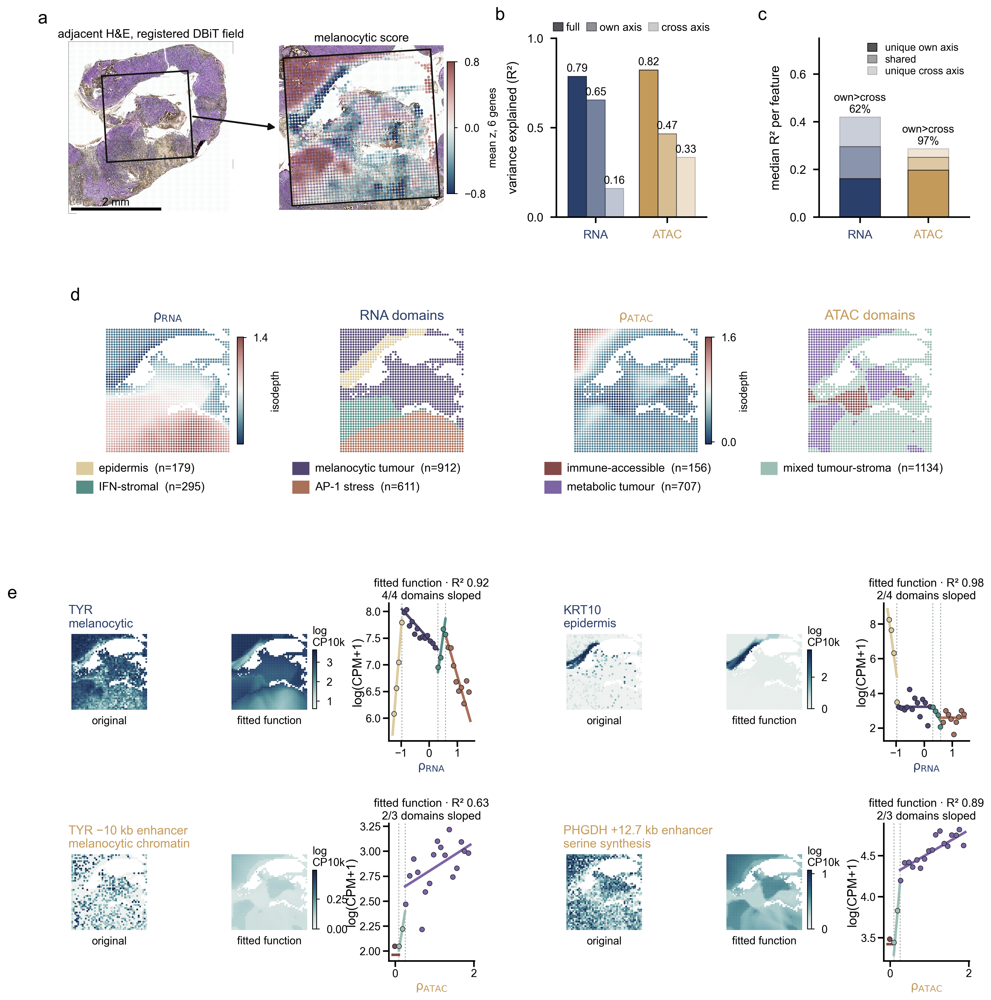

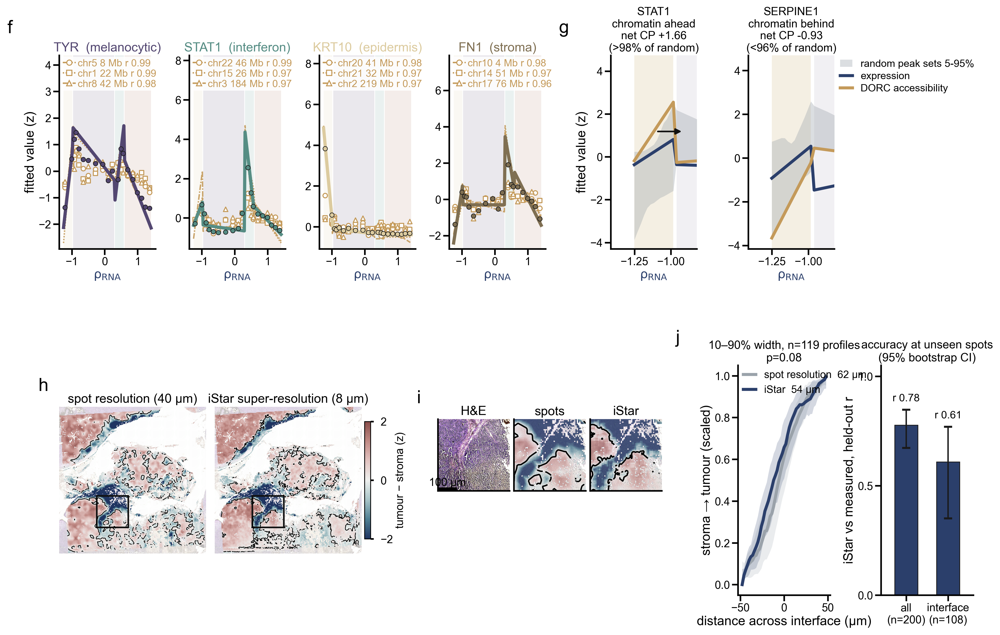

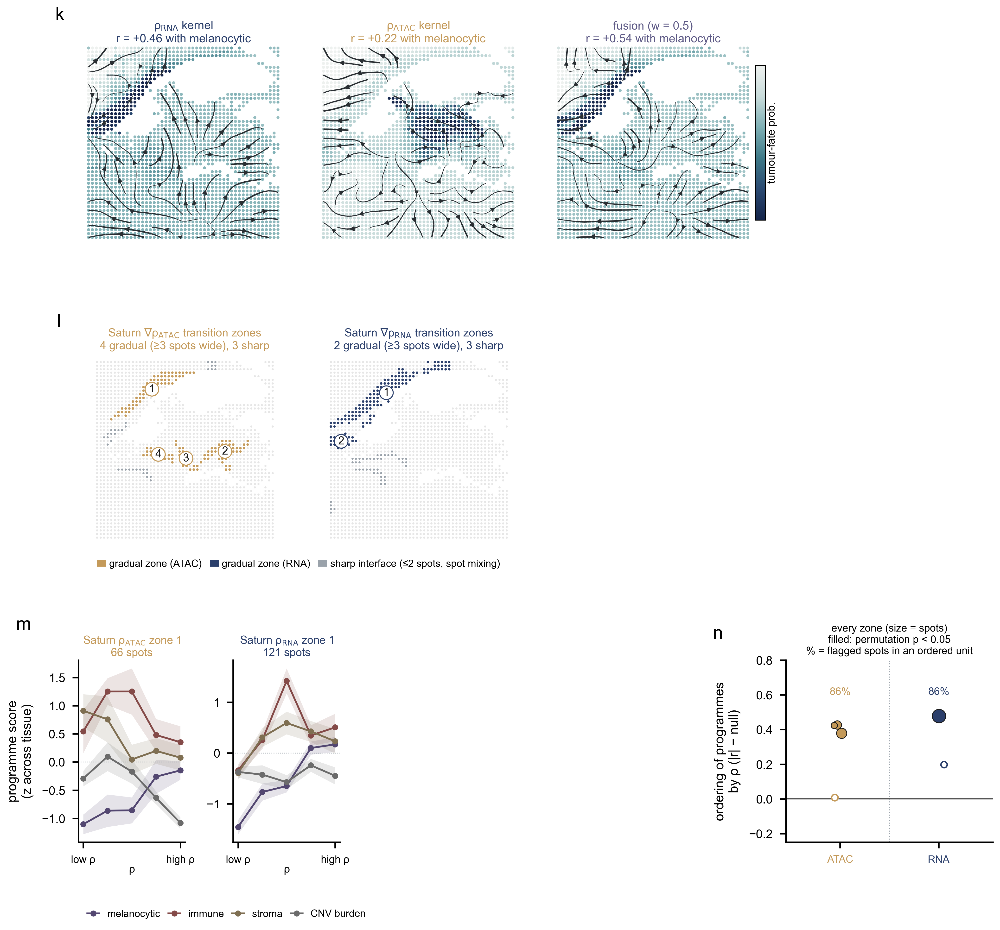

In [9]:
nb.step("figure", f"python {STEPS}/fig3_saturn_panels.py", [str(nb.PF / "fig3/fig3_saturn_stats.json")])
if nb.PUB:
    chk.istar_stats(); chk.png_identical("fig3/fig3_part1.png", "fig3/fig3_part2.png")
nb.show("fig3/fig3_part1.png", "fig3/fig3_part2.png", "fig3/fig3_part3.png")